# Agentic RAG Research Assistant — capstone

**A question-answering system over 2,012 arXiv machine-learning papers that
retrieves evidence before it answers, cites its sources, and — agentically —
decides for itself how to search.**

> **Executive summary — three findings.**
>
> **1. The retriever this system ships is the wrong default.** Benchmarked against
> three alternatives on 191 questions, a 1990s lexical baseline (BM25) beats it on
> every metric at one-eighth the latency: **nDCG@10 0.978 [0.962, 0.992] at 2.0 ms**
> versus **0.751 [0.691, 0.811] at 17.4 ms**. Paired per question, that gap is
> +0.227 with **52 wins to 1 loss**, p < 0.001. The cross-encoder reranker — which
> an earlier version of this project recommended as the obvious next step — buys
> **no measurable quality over BM25** (+0.014, p = 0.10) while charging about
> **1,200× its latency**.
>
> **2. A single retrieval structurally fails on a compound question.** Single-shot
> retrieval recovers only **60%** of the needed papers on multi-hop questions,
> because one search embeds the whole compound question as a single point.
> Swapping the retriever recovers part of that gap; the rest is what the **agent**
> is for.
>
> **3. The project's own drift monitor was broken, and acting on it is what proved
> it.** The probe read a 27.2% similarity drop against a 15% re-index trigger, so
> the index was rebuilt — and the same probe read 26.7% on an index one hour old.
> The metric had a structural floor and could never have said anything else. It now
> triggers on excess over a *measured* floor.

This notebook runs top-to-bottom on a fresh kernel. It imports everything from
`src/` (so it can never disagree with the scripts and tests), reproduces the
retrieval numbers **live and locally**, and treats the Claude-backed answer steps
as reference-only — they run if `ANTHROPIC_API_KEY` is set and otherwise degrade
gracefully, exactly like the portfolio's GPU-trained notebooks.

This is a **hybrid** project: the RAG pipeline is the engineering track, and the
**evaluation harness carries it** — the questions it answers are which retrieval
strategy is actually worth its latency, whether the gaps between them survive a
significance test, where the cutoffs should sit, whether the chunking constant was
worth anything, and whether a multi-step agent beats a single-shot one.


## 0 · Setup

Make `src/` importable and load the config — the single place every tuned constant lives.

In [1]:
import sys, json
from pathlib import Path

# Make the project root importable whether the kernel started in notebooks/ or root.
ROOT = Path.cwd()
if (ROOT / "src").exists():
    pass
elif (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config
print("Project root:", ROOT)
print("Embedding model:", config.EMBED_MODEL, f"(dim {config.EMBED_DIM})")
print("Chunk size / overlap:", config.CHUNK_SIZE_CHARS, "/", config.CHUNK_OVERLAP_CHARS, "chars")
print("Retrieval top-k:", config.TOP_K, " | max agent steps:", config.MAX_AGENT_STEPS)
print("Generation model:", config.GEN_MODEL, " | API key present:", config.api_key_available())

Project root: D:\Claude\Data Science Projects\01-projects\agentic-rag-research-assistant
Embedding model: sentence-transformers/all-MiniLM-L6-v2 (dim 384)
Chunk size / overlap: 1000 / 150 chars
Retrieval top-k: 5  | max agent steps: 4
Generation model: claude-sonnet-5  | API key present: False


## 1 · Problem framing

A large language model answering from memory is a student sitting a closed-book
exam: fluent, and confidently wrong on specifics. **RAG turns it open-book** — fetch
the relevant passages first, then answer *from them*, with citations.

The decision this project interrogates is one level up: **once you retrieve, should
you retrieve *once* (naive RAG) or let the model decide how to retrieve, iterating
as needed (agentic RAG)?** The agent is more capable but costs more calls. Is it
worth it — and *where*? Our sub-questions:

1. Where does single-shot retrieval actually fail? *(§4 — the finding)*
2. Can an agent that decomposes and re-searches recover those failures? *(§5)*
3. What does that cost? *(§5 — the trade-off)*

## 2 · Data — the corpus and its provenance

We index recent cs.CL / cs.LG papers from the arXiv API, plus 12 seeded seminal
papers (Transformer, BERT, RAG, DPR, ReAct, …) so the evaluation's ground-truth
answers are guaranteed present. Everything is loaded through `src/` with the same
provenance the pipeline records — nothing is re-implemented here.

In [2]:
from src import acquisition

prov = json.load(open(config.PROVENANCE_FILE))
print("Source:", prov["source"])
print("Categories:", prov["categories"])
print("Downloaded (UTC):", prov["downloaded_utc"])
print("Papers:", prov["paper_count"])
print("Corpus SHA-256:", prov["papers_sha256"][:16], "...")

papers = acquisition.load_papers()
print("\nExample seeded paper:")
seed = next(p for p in papers if p.arxiv_id == "2005.11401")  # the RAG paper
print(" ", seed.arxiv_id, "—", seed.title)
print(" ", seed.abstract[:220], "...")

Source: arXiv API (http://export.arxiv.org/api/query)
Categories: ['cs.CL', 'cs.LG']
Downloaded (UTC): 2026-08-12T14:11:51.341691+00:00
Papers: 2012
Corpus SHA-256: b5248118d64c3e3f ...

Example seeded paper:
  2005.11401 — Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks
  Large pre-trained language models have been shown to store factual knowledge in their parameters, and achieve state-of-the-art results when fine-tuned on downstream NLP tasks. However, their ability to access and precise ...


## 3 · The RAG pipeline — how a question finds its evidence

Build-time (already run by `run_pipeline.py`): **chunk → embed → index**. We reuse
`inspect.getsource` to show the real chunking code, so the explanation can never
drift from what actually ran.

In [3]:
import inspect
from src import chunking

print(inspect.getsource(chunking.split_text))

def split_text(text: str,
               size: int = config.CHUNK_SIZE_CHARS,
               overlap: int = config.CHUNK_OVERLAP_CHARS) -> list[str]:
    """Slice `text` into overlapping windows of `size` characters.

    Each window starts `size - overlap` characters after the previous one, so
    consecutive chunks share `overlap` characters. That shared margin is what
    stops a fact that straddles a boundary from being lost — it survives in at
    least one chunk. We try to end each window at a whitespace boundary so chunks
    don't split mid-word, which would corrupt the embedding.

    Guarding the two edge cases explicitly: overlap must be smaller than size (or
    the window never advances and we loop forever), and text shorter than one
    window is returned as a single chunk.
    """
    if overlap >= size:
        raise ValueError(f"overlap ({overlap}) must be smaller than size ({size})")

    text = text.strip()
    if len(text) <= size:
        return [text] if text else

Every chunk carries its paper's id and title — that metadata is what lets an
answer *cite* the passage it used. Now load the built index (the vector store) and
run one live retrieval to see semantic search work.

In [4]:
from src.vectorstore import VectorStore

store = VectorStore.load()
print("Index:", store.size, "chunks\n")

# A query whose words barely overlap the target passage — semantic search, not keywords.
hits = store.search("how do neural networks pay attention to parts of a sequence", k=3)
for h in hits:
    print(f"[{h.arxiv_id}] score={h.score:.3f}  {h.title}")
    print("   ", h.text[:150], "...\n")

Index: 4298 chunks



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[2608.09690] score=0.527  Recurrent Neural Networks Beyond Time: Learning from Multiple Ordered Projections
    Recurrent Neural Networks Beyond Time: Learning from Multiple Ordered Projections

Recurrent neural networks (RNNs) are widely used for sequence learn ...

[2608.09690] score=0.503  Recurrent Neural Networks Beyond Time: Learning from Multiple Ordered Projections
    l. As a concrete realization, we present Structural Evolution RNNs (SE-RNNs), which employ conventional RNNs as projection-specific structural experts ...

[2608.06776] score=0.494  Faster Query-Key Learning Sharpens Attention in Self-Attention Models
    Faster Query-Key Learning Sharpens Attention in Self-Attention Models

A standard self-attention layer consists of two interacting circuits: the query ...



## 4 · EDA / the finding — where single-shot retrieval breaks

This is the load-bearing result. For each evaluation question we know which
paper(s) genuinely answer it (`eval/qa_set.json`), so we can measure whether
retrieval surfaced them — **hit@k**, **recall@k**, **MRR** — all computed locally
with no API key, through `src/evaluation.py`.

In [5]:
from src import evaluation as ev
import pandas as pd

questions = ev.load_eval_set()
retrieval_rows = ev.evaluate_retrieval(store, questions)
df = pd.DataFrame(retrieval_rows)

summary = df.groupby("hop")[["hit@k", "recall@k", "mrr"]].mean().round(3)
summary.loc["all"] = df[["hit@k", "recall@k", "mrr"]].mean().round(3)
summary

,hit@k,recall@k,mrr
hop,,,
multi,0.800,0.600,0.600
single,0.833,0.833,0.833
all,0.818,0.727,0.727


**Read this table carefully — it is the whole argument.** Multi-hop recall@5 is
**0.60**: when a question needs two papers, a single search typically grabs only
one of them. The compound question embeds to one point in the vector space; the
second, differently-phrased piece of evidence lives elsewhere and never surfaces.

Single-hop recall is **0.83**, and the single question that fails is worth more
than the average. It is `s5` — the *word2vec* question — and section 5 will
identify it independently, for a completely different reason, as the corpus's one
vocabulary-mismatch case. Two measurements taken for different purposes landing on
the same row is the strongest kind of corroboration a small eval set can offer.

The per-question breakdown makes the failure concrete — the rows with recall below
1.0 are the ones to read:


In [6]:
df[df.hop == "multi"][["qid", "hit@k", "recall@k", "mrr"]].round(2)

,qid,hit@k,recall@k,mrr
6,m1,1.0,1.0,0.5
7,m2,1.0,0.5,1.0
8,m3,1.0,0.5,0.5
9,m4,0.0,0.0,0.0
10,m5,1.0,1.0,1.0


On `m4` (attention *before* vs *after* the Transformer) single-shot retrieval
recall is **0.0** — it missed both papers. That is precisely the kind of question an
agent should rescue by searching for "attention before the Transformer" separately
from "what the Transformer changed". The committed figure visualizes the gap:


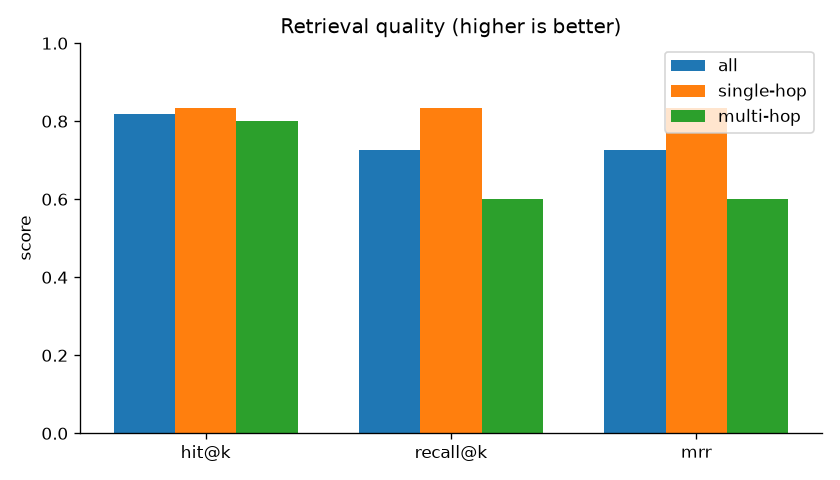

In [7]:
from IPython.display import Image
Image(filename=str(config.FIGURES_DIR / "01_retrieval_metrics.png"))

## 5 · Benchmarking retrieval — four arms, and the baseline that won

Section 4 showed *the shipped retriever* failing on multi-hop questions. It never
asked the more basic question: **is this retriever any good in the first place?**

Almost no public RAG notebook asks it either. The pattern is to wire an embedding
model to a vector store, retrieve top-k, hand it to an LLM and show one impressive
answer — with no baseline to beat, no confidence interval, and no latency. A RAG
demo is a commodity; a defensible evaluation of one is not.

So we benchmark four arms, each the previous one **plus exactly one idea**, so a
change in the score can be attributed to a cause:

| Arm | What it adds | Implemented in |
|---|---|---|
| `dense` | semantic matching | delegates to `VectorStore.search` — the *same* code path the system ships |
| `bm25` | literal term overlap | `src/lexical.py` — BM25 Okapi written out, k1/b at the Lucene defaults |
| `hybrid` | fusing the two rankings | reciprocal-rank fusion, `Σ 1/(60 + rank)` |
| `rerank` | reading query and document jointly | cross-encoder over the hybrid shortlist |

An arm that added two ideas at once would be unattributable — which is why there
is no "hybrid + query expansion + reranking" arm.

In [8]:
from src import retrievers

arms = retrievers.build_all(store)
demo_q = "What neural network architecture did Attention Is All You Need introduce?"

for arm in arms:
    hits = arm.search(demo_q, k=3)
    print(f"[{arm.name}]")
    for h in hits:
        print(f"   {h.arxiv_id}  {h.score:>8.3f}  {h.title[:64]}")
    print()

[dense]
   2608.09432     0.517  ZetaGPT: A Reference Implementation of Positional--Encoding--Fre
   2608.04678     0.510  Kathleen Writes: Autoregressive Generation and Data Scaling With
   2608.03294     0.506  Provably Learning Multi-Head Attention with Queries

[bm25]
   1706.03762    22.454  Attention Is All You Need
   2608.01252    16.043  AdaHAT: Adaptive Hard Attention to the Task in Task-Incremental 
   2608.10969    14.952  GARLIC: Graph Attention-based Relational Learning of Multivariat

[hybrid]
   2608.04678     0.032  Kathleen Writes: Autoregressive Generation and Data Scaling With
   1706.03762     0.031  Attention Is All You Need
   2608.01252     0.030  AdaHAT: Adaptive Hard Attention to the Task in Task-Incremental 



Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[rerank]
   1706.03762     5.544  Attention Is All You Need
   2608.01252    -0.959  AdaHAT: Adaptive Hard Attention to the Task in Task-Incremental 
   2608.01252    -1.045  AdaHAT: Adaptive Hard Attention to the Task in Task-Incremental 



**Already visible on a single query:** the dense arm — the one this project ships —
does not return *Attention Is All You Need* for a question that names it. BM25 puts
it first. That is not a fluke, and the rest of this section quantifies it.

### The full benchmark

Scored on **180 generated known-item queries** (`src/evalset.py`) plus the 11
hand-written ones, at k=10, with 2,000-resample bootstrap intervals.

The cross-encoder arm takes ~2.6 s per query, so the full run is a script rather
than a notebook cell — the same "reference-only, load the saved result" convention
this portfolio uses for GPU-trained notebooks. Regenerate with
`python run_retrieval_bench.py`; every number below is read from its committed
output.

In [9]:
import json

with open(config.ARM_SUMMARY_FILE, encoding="utf-8") as f:
    arm_summary = pd.DataFrame(json.load(f))

overall = arm_summary[arm_summary.slice == "all"].set_index("arm")
overall["nDCG@10 (95% CI)"] = [
    f"{r['ndcg@k']:.3f}  [{r['ndcg@k_lo']:.3f}, {r['ndcg@k_hi']:.3f}]"
    for _, r in overall.iterrows()
]
overall[["nDCG@10 (95% CI)", "ap@k", "recall@k", "mrr", "latency_ms_median"]].rename(
    columns={"ap@k": "MAP", "recall@k": "recall@10",
             "mrr": "MRR", "latency_ms_median": "median ms"}
).round(3)

,nDCG@10 (95% CI),MAP,recall@10,MRR,median ms
arm,,,,,
dense,"0.751 [0.691, 0.811]",0.738,0.794,0.738,17.418
bm25,"0.978 [0.962, 0.992]",0.971,1.000,0.971,1.970
hybrid,"0.874 [0.835, 0.911]",0.844,0.967,0.844,18.345
rerank,"0.964 [0.942, 0.982]",0.954,0.994,0.954,2465.018


**The 1990s lexical baseline beats the embedding model this system ships — on
every metric, at one-eighth the latency.**

Resist reading the intervals against each other, though. Two marginal intervals
overlapping does *not* mean two arms are indistinguishable, and the next cells
make that comparison properly. First, the trade-off itself:


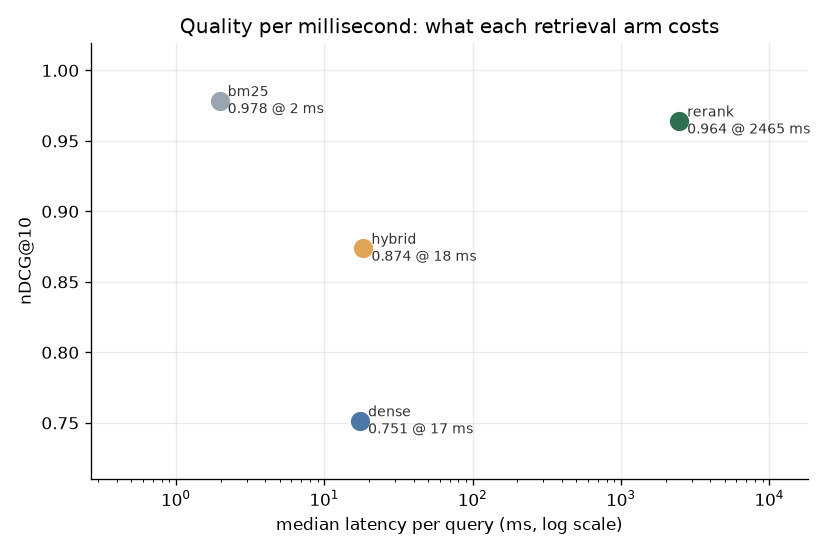

In [10]:
Image(filename=str(config.FIGURES_DIR / "05_quality_vs_latency.png"))

In [11]:
from src import significance

with open(config.SIGNIFICANCE_FILE, encoding="utf-8") as f:
    sig_records = json.load(f)

significance.significance_table(sig_records)

,comparison,diff nDCG@10,95% CI,wins/losses/ties,p (Holm),significant
0,bm25 vs dense,0.227,"[0.171, 0.286]",52/1/127,0.0006,yes
1,rerank vs dense,0.213,"[0.160, 0.272]",51/1/128,0.0006,yes
2,hybrid vs dense,0.122,"[0.090, 0.156]",46/0/134,0.0006,yes
3,bm25 vs hybrid,0.105,"[0.071, 0.141]",37/1/142,0.0006,yes
4,rerank vs hybrid,0.090,"[0.057, 0.127]",34/5/141,0.0006,yes
5,bm25 vs rerank,0.014,"[-0.001, 0.033]",8/6/166,0.1010,no


**The bottom row changed a conclusion.** On the point estimates BM25 (0.978) sits
above the cross-encoder (0.964), and an earlier version of this project said so —
that the reranker "scores lower". Paired, that gap is **8 wins against 6 losses
over 166 ties**, and it does not survive its own significance test.

So the defensible claim is not that BM25 beats the reranker. It is:

> **the cross-encoder buys no measurable quality over BM25, and charges about
> 1,200× the latency for it.**

That is the *stronger* statement. "Slightly better" invites an argument about
whether the difference is worth paying for; "no measurable difference at a
thousand times the price" ends it.

Note also the wins/losses column, which a mean cannot show you: `hybrid vs dense`
is **46–0**. An arm that never once loses is a different thing from an arm that
wins twice enormously, and only the per-question view distinguishes them.

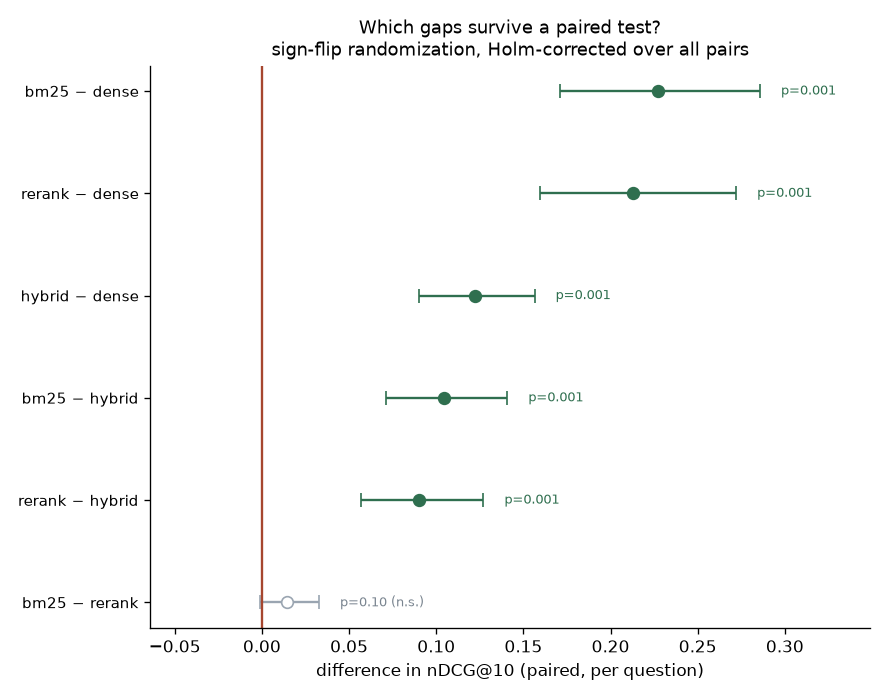

In [12]:
Image(filename=str(config.FIGURES_DIR / "08_arm_significance.png"))

BM25 is the top-left point: **nothing else buys quality it does not already have,
and everything else costs more.**

### Is any of that gap real?

Every arm answered the *same* 180 questions, so the per-question **difference**
exists — and it is a much sharper instrument than four intervals side by side.
Question difficulty is shared by both arms in any pair, so it cancels in the
difference; that shared variance is most of what makes the marginal intervals
wide.

`src/significance.py` compares every pair with a **sign-flip randomization test**
(the null is that the two arms are interchangeable, so the sign of each question's
difference is arbitrary — flip them at random 10,000 times and see how extreme the
real mean is) and a **Holm correction** across all six pairs, because six tests at
α = 0.05 is a ~26% chance of at least one false positive.


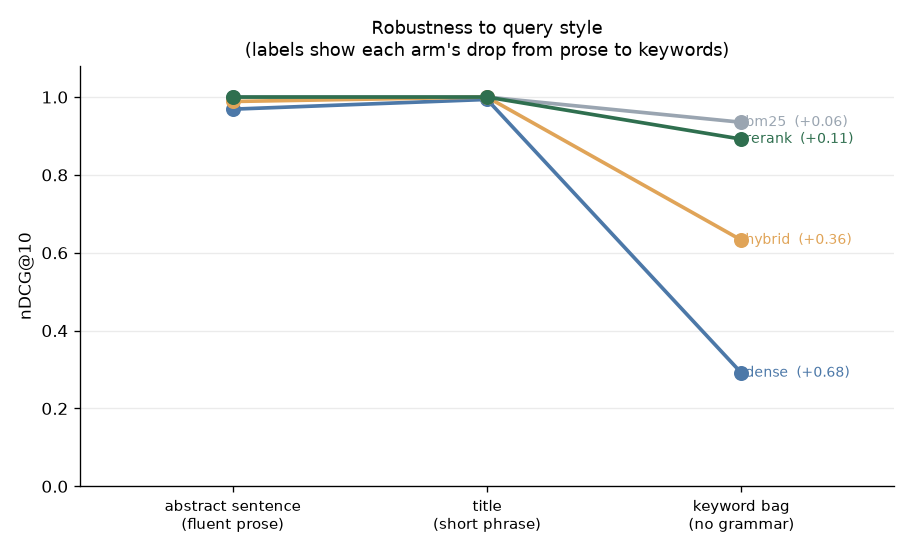

In [13]:
Image(filename=str(config.FIGURES_DIR / "06_query_style_robustness.png"))

In [14]:
with open(config.K_SWEEP_FILE, encoding="utf-8") as f:
    sweep = pd.DataFrame(json.load(f))

sweep.pivot(index="k", columns="arm", values="recall@k")[
    ["dense", "bm25", "hybrid", "rerank"]
].round(3)

arm,dense,bm25,hybrid,rerank
k,,,,
1,0.711,0.956,0.794,0.928
3,0.750,0.978,0.872,0.983
5,0.778,1.000,0.917,0.994
10,0.800,1.000,0.967,0.994
20,0.822,1.000,1.000,1.000
50,0.856,1.000,1.000,1.000


Three answers no fixed-k table could give:

1. **Serving 5 costs nothing under BM25** — its recall is already 1.000 at k=5, so
   the gap between the cutoff the system serves and the one the benchmark reports
   hides no losses. Under the *dense* arm it would (0.778 at 5 against 0.800 at 10).
2. **The dense arm never saturates.** At k=50 it has found 85.6% of the target
   papers. That is a **recall ceiling**, not a ranking problem — and it is the
   mechanical reason a reranker cannot rescue it. A cross-encoder reorders what it
   is handed; it cannot retrieve what the first stage never returned.
3. **The reranker's shortlist is over-provisioned.** Hybrid recall reaches 1.000 by
   k=20, so nothing beyond rank 20 is ever needed. `RERANK_CANDIDATES` could be 20
   instead of 50 — roughly 2.5× less cross-encoder work at no cost in recall.

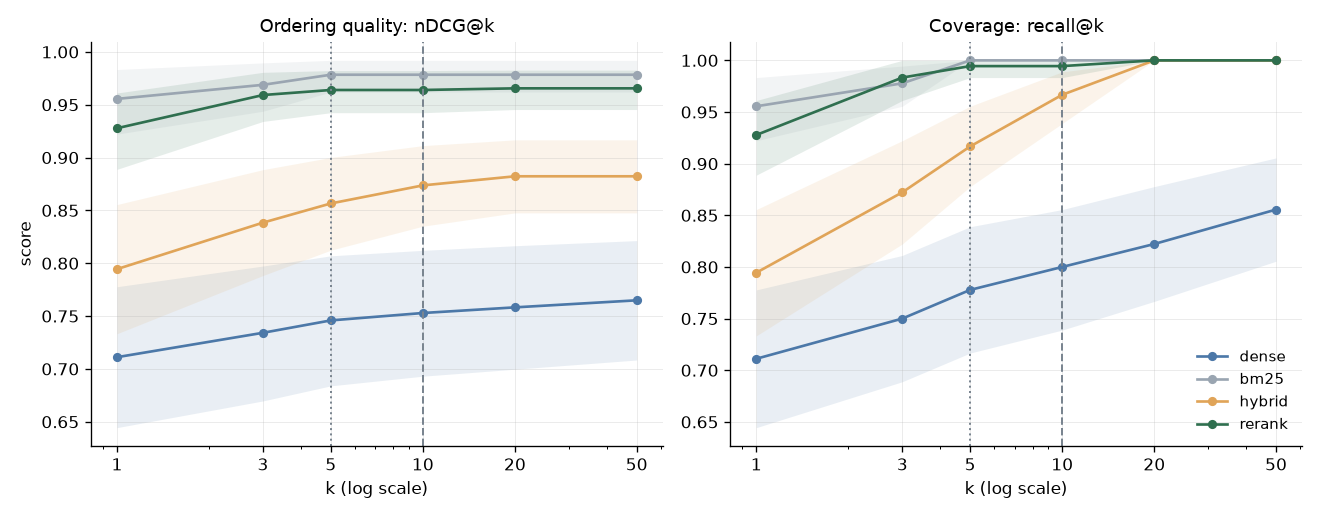

In [15]:
Image(filename=str(config.FIGURES_DIR / "09_k_sweep.png"))

BM25 never reads word order at all, so it barely moves (**−0.065**). The dense arm
loses **two-thirds of its quality** (0.969 → 0.291) once the query stops being a
sentence. A bi-encoder trained on natural prose has no particular reason to handle
a keyword bag well, and it doesn't.

### How deep do you have to look? The cutoff sweep

Everything so far is reported at k=10. Why 10? Because BEIR and TREC report there —
a fine reason to *report* at 10 and no reason at all to believe it is where the
interesting behaviour is. Meanwhile the system serves the top **5** chunks to the
LLM (`config.TOP_K`) and the reranker rescores a shortlist of **50**
(`config.RERANK_CANDIDATES`). Three constants, all argued in `config.py`, none
measured against each other.

`evaluation.sweep_k` searches **once** at k=50 per (arm, question) and truncates
the ranking at each cutoff — so the *cutoff* is the only thing varying. Searching
separately per k would confound it with "a retriever configured for k", which the
reranker genuinely is.


In [16]:
with open(config.RESULTS_DIR / "arm_comparison_curated.json", encoding="utf-8") as f:
    curated_rows = pd.DataFrame(json.load(f))

curated_rows.pivot(index="qid", columns="arm", values="recall@k")[
    ["dense", "bm25", "hybrid", "rerank"]
].join(curated_rows.groupby("qid")["hop"].first()).sort_values(["hop", "qid"])

,dense,bm25,hybrid,rerank,hop
qid,,,,,
m1,1.0,1.0,1.0,1.0,multi
m2,1.0,1.0,1.0,1.0,multi
m3,1.0,1.0,1.0,1.0,multi
m4,0.0,0.5,0.5,0.5,multi
m5,1.0,1.0,1.0,1.0,multi
s1,1.0,1.0,1.0,1.0,single
s2,1.0,1.0,1.0,1.0,single
s3,1.0,1.0,1.0,1.0,single
s4,1.0,1.0,1.0,1.0,single


Two rows matter more than the average.

**`s5` — the one question BM25 cannot answer.** It asks what **word2vec** learns.
The correct paper is *"Efficient Estimation of Word Representations in Vector
Space"*, and the string `word2vec` appears **zero times in all 4,298 chunks**. BM25
cannot match a term that is not there and scores 0.00; the dense arm does find it,
around rank 6, because *word2vec* and *word representations in vector space* are
near-neighbours in embedding space.

That is the canonical **vocabulary-mismatch** case — the exact problem dense
retrieval was invented to solve — appearing live in an evaluation whose headline
says dense retrieval lost. Hybrid RRF inherits BM25's failure rather than dense's
success: fusion is not free insurance.

It is also the same question section 4 found failing at `TOP_K = 5`, where rank 6
is one place outside what the system actually serves. So on this corpus `s5` is
unanswerable by the shipped system *and* by the lexical baseline, for opposite
reasons.

**`m4` — the question section 4 showed failing completely.** Dense scores 0.00; BM25
recovers one of the two papers. Swapping the retriever fixes half of the multi-hop
gap with no agent at all — and the remaining half is a genuine two-paper problem
that no single retrieval strategy solves. That residue is the agent's case.

### Does the chunk size actually matter?

`config.CHUNK_SIZE_CHARS = 1000` carries a paragraph of justification — too large
and one vector must average several ideas, too small and a sentence loses the
context that made it meaningful — and, until this run, zero measurement. It is the
one build-time decision that moves *both* arms, for different reasons: embedding
dilution for dense, and document-length normalisation for BM25, since chunk size
*is* document length.

`run_ablation.py` rebuilds the corpus at five sizes — re-chunk, re-embed, re-index
each time — and scores dense and BM25 on the same questions. The cross-encoder is
excluded on cost, and that exclusion is stated rather than left to be noticed.


In [17]:
with open(config.CHUNK_ABLATION_FILE, encoding="utf-8") as f:
    ablation = pd.DataFrame(json.load(f))

ablation.pivot(index="chunk_size", columns="arm", values="ndcg@k").round(3).join(
    ablation.groupby("chunk_size")["n_chunks"].first()
)

,bm25,dense,n_chunks
chunk_size,,,
400,0.942,0.758,9810
700,0.972,0.748,5895
1000,0.978,0.751,4298
1400,0.996,0.726,3388
2000,0.998,0.725,2082


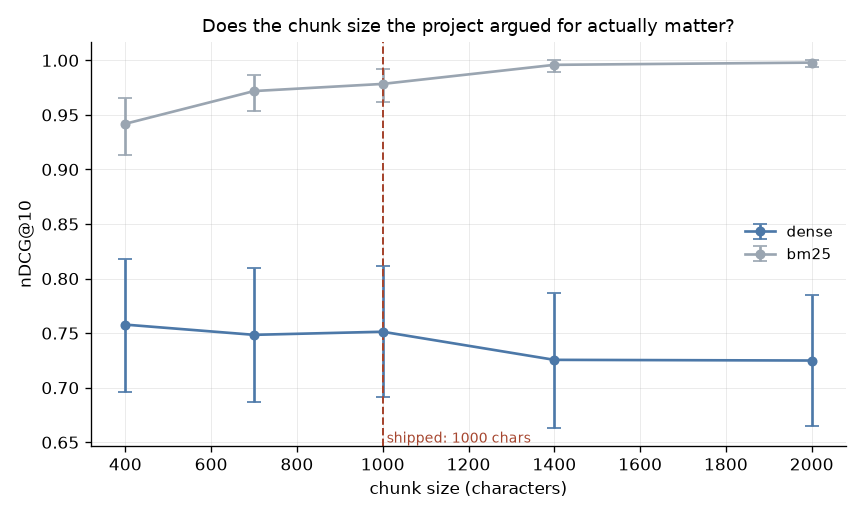

In [18]:
Image(filename=str(config.FIGURES_DIR / "10_chunk_ablation.png"))

**The two arms want opposite things**, and the same paired discipline as before
says which of the two movements is real:

In [19]:
with open(config.ABLATION_SIGNIFICANCE_FILE, encoding="utf-8") as f:
    ablation_tests = pd.DataFrame(json.load(f))

ablation_tests[["arm", "chunk_size", "mean_diff", "mean_diff_lo", "mean_diff_hi",
                "n_better", "n_worse", "n_ties", "p_value_holm", "significant"]].round(4)

,arm,chunk_size,mean_diff,mean_diff_lo,mean_diff_hi,n_better,n_worse,n_ties,p_value_holm,significant
0,dense,400,0.0065,-0.0150,0.0319,12,12,156,1.0000,False
1,dense,700,-0.0028,-0.0203,0.0149,9,8,163,1.0000,False
2,dense,1400,-0.0258,-0.0514,-0.0012,8,17,155,0.1804,False
3,dense,2000,-0.0264,-0.0554,0.0012,10,19,151,0.2292,False
4,bm25,400,-0.0365,-0.0564,-0.0165,2,17,161,0.0004,True
5,bm25,700,-0.0066,-0.0169,0.0030,3,6,171,0.2263,False
6,bm25,1400,0.0175,0.0039,0.0333,8,1,171,0.0500,True
7,bm25,2000,0.0195,0.0071,0.0346,8,0,172,0.0255,True


### How long do these numbers stay true?

Every number above describes an index built on a particular day, over a literature
that does not stop. `src/drift.py` compares mean top-1 similarity for queries drawn
from **indexed** papers against queries drawn from **newer, unseen** ones, and
turns the gap into a re-indexing trigger.

**This is the part of the project that was wrong, and finding out required acting
on it.** The previous index (2026-07-27) read a 27.2% drop against a flat 15%
trigger, so the README recommended a rebuild. The rebuild happened — against a
corpus sharing not one paper with the old one:


In [20]:
with open(config.RESULTS_DIR / "corpus_turnover.json", encoding="utf-8") as f:
    turnover = json.load(f)

print(f"old index      : {turnover['old_index_built_utc'][:10]}")
print(f"new index      : {turnover['new_index_built_utc'][:10]}")
print(f"papers sampled : {turnover['n_sampled']} (the old eval set's target papers)")
print(f"still present  : {turnover['n_still_present']}  "
      f"-> {turnover['survival_rate']:.0%} survived")
print(f"seeded papers  : {turnover['seeded_papers_present']}"
      f"/{turnover['seeded_papers_expected']} present in both, by construction")

old index      : 2026-07-27
new index      : 2026-08-12
papers sampled : 60 (the old eval set's target papers)
still present  : 0  -> 0% survived
seeded papers  : 12/12 present in both, by construction


**Complete turnover in 16 days.** The corpus is the newest `MAX_PAPERS` in cs.CL
and cs.LG, and arXiv publishes more than that in a fortnight, so the window rotated
entirely. Only the 12 papers pinned by id survived — which is exactly why they are
pinned, and why the 11 curated questions still mean the same thing after a rebuild.

So: a brand-new index, over a completely different corpus. Here is what the drift
probe says about it.

indexed papers : 0.725 mean top-1 similarity
newer papers   : 0.531
relative drop  : 26.7%
day-zero floor : 26.7%   <- what this probe reads on a brand-new index
excess         : +0.05%  (trigger at +10%)
verdict        : at the floor - nothing to do


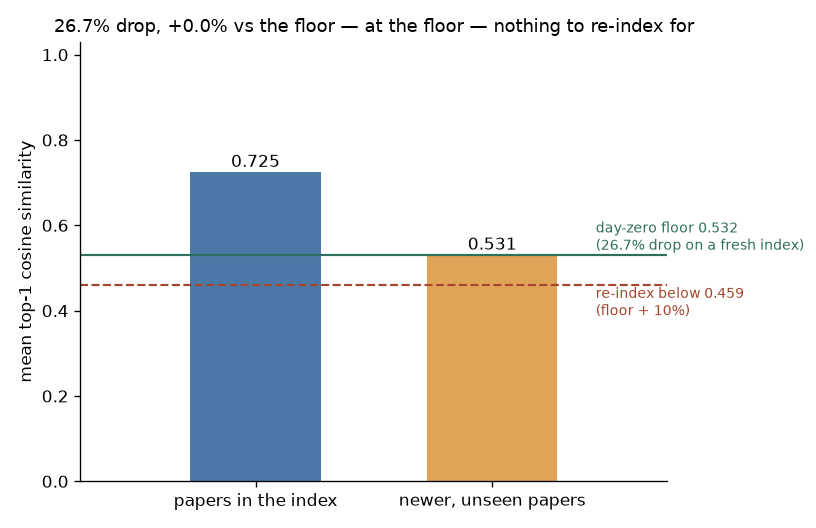

In [21]:
with open(config.DRIFT_RESULTS_FILE, encoding="utf-8") as f:
    drift_record = json.load(f)

print(f"indexed papers : {drift_record['baseline_top1_mean']:.3f} mean top-1 similarity")
print(f"newer papers   : {drift_record['probe_top1_mean']:.3f}")
print(f"relative drop  : {drift_record['relative_drop']:.1%}")
print(f"day-zero floor : {drift_record['floor_relative_drop']:.1%}"
      "   <- what this probe reads on a brand-new index")
print(f"excess         : {drift_record['excess_over_floor']:+.2%}"
      f"  (trigger at {drift_record['trigger_excess']:+.0%})")
print(f"verdict        : {'RE-INDEX' if drift_record['reindex_now'] else 'at the floor - nothing to do'}")

Image(filename=str(config.FIGURES_DIR / "07_drift.png"))

**The drop barely moved: 27.2% on the old index, 26.7% on one built an hour ago.**

The largest freshness intervention that exists — replacing every paper in the
corpus — changed the metric by half a percentage point. That is not an index
result, it is a *metric* result: the raw drop was never measuring staleness.

The reason is structural. A baseline query is a sentence lifted verbatim out of a
document sitting *in* the index, so its top-1 match is a near-self-match by
construction. A probe query comes from a document that is absent by definition, so
its best match is the closest topical neighbour. The gap between "verbatim
self-match" and "nearest neighbour" is a property of the measurement, present in
full on day zero — so a threshold on it fires on every index, always, and
distinguishes nothing.

The trigger now tests the **excess over a measured day-zero floor** (0.267 —
observed on the fresh index, not assumed). This index reads **+0.05 percentage
points**: nothing to do.

Two things worth taking from this beyond the fix:

- **The bug was findable from the start.** `drift.py`'s own docstring always said
  "the gap *widening* is the signal", and the code thresholded the level anyway.
  The prose was right and unread; the code was wrong and trusted.
- **The floor expires.** Change the embedding model, the chunk size or the corpus
  size and it silently stops being the right number, while the constant in
  `config.py` stays put. That makes it the most fragile line in the project, which
  is written down next to it rather than left to be discovered.

> **How the questions were labelled, and where they mislead**, is written up in
> [`eval/ADJUDICATION.md`](../eval/ADJUDICATION.md). The short version: every
> generated query is built from its target document's own words, which
> structurally favours BM25. Three things make the finding survivable — the three
> query styles measure a *slope* rather than a single point, the hand-written set
> (which does not share that bias) agrees, and the whole result replicated on a
> corpus with zero overlap.


## 6 · Method & the head-to-head — naive vs agentic RAG

Both systems share the **same** `VectorStore.search` (one definition of retrieval in
the repo), so any difference between them is about the *strategy*, not the search.

**Naive RAG** retrieves once and generates once. **Agentic RAG** runs a from-scratch
Claude tool-use loop: it decomposes the question, searches for each part, reads the
results, searches again if needed (up to `MAX_AGENT_STEPS`), then answers. Here is
the actual loop that does it — no framework, fully inspectable:

In [22]:
from src import agent as agent_mod
print(inspect.getsource(agent_mod.answer))

def answer(store: VectorStore, question: str, k: int = config.TOP_K) -> AgentAnswer:
    """Run the agentic loop and return the answer plus its search trace.

    This is a manual Claude tool-use loop: we call the model, and while it keeps
    asking to use the search tool we run the search and feed the results back,
    appending every turn to the running message history. The loop is bounded by
    MAX_AGENT_STEPS so a confused agent can't retrieve forever — after the cap we
    ask it once more, tools disabled, to answer with what it has.
    """
    messages: list[dict[str, Any]] = [{"role": "user", "content": question}]
    steps: list[AgentStep] = []
    all_hits: dict[str, Retrieved] = {}   # de-dupe the evidence pool by chunk_id

    for _ in range(config.MAX_AGENT_STEPS):
        # Inside the loop the search tool is always offered; the model itself
        # decides whether to search again or answer. The step cap below is the
        # backstop if it never chooses to stop searc

### Running the two systems

The retrieval above is local and always reproduces. **Generation needs an Anthropic
API key.** The next cell is *reference-only*: with a key it runs both systems live
and shows the agent's search trace; without one it explains what would run and
skips gracefully, so Restart & Run All succeeds either way.

In [23]:
from src import rag
from src.llm import LLMKeyMissing

question = ("How does retrieval-augmented generation combine a dense passage "
            "retriever with a sequence-to-sequence generator?")

if config.api_key_available():
    naive = rag.answer(store, question)
    print("=== NAIVE RAG ===")
    print(naive.answer)
    print("cited:", naive.cited_ids, "\n")

    agentic = agent_mod.answer(store, question)
    print("=== AGENTIC RAG — search trace ===")
    for i, step in enumerate(agentic.steps, 1):
        print(f"  step {i}: {step.query!r} -> {[h.arxiv_id for h in step.hits]}")
    print(f"  (stopped: {agentic.stopped_reason})")
    print("\n=== AGENTIC ANSWER ===")
    print(agentic.answer)
    print("cited:", agentic.cited_ids)
else:
    print("No ANTHROPIC_API_KEY set — generation is reference-only in this run.")
    print("With a key, this cell runs both systems and prints the agent's search")
    print("trace: you would see it search for the *retriever* and the *generator*")
    print("separately, recovering the second paper that single-shot retrieval (\u00a74)")
    print("misses on this exact multi-hop question.")

No ANTHROPIC_API_KEY set — generation is reference-only in this run.
With a key, this cell runs both systems and prints the agent's search
trace: you would see it search for the *retriever* and the *generator*
separately, recovering the second paper that single-shot retrieval (§4)
misses on this exact multi-hop question.


### The evaluation harness (design)

`run_eval.py` runs both systems over every question and grades the answers with an
LLM-as-judge on **groundedness** (is every claim supported by the sources?) and
**correctness** (does it answer the question?), split by hop type, alongside the
agent's retrieval count. Results are cached and committed so they reproduce without
a key. The hypothesis the harness tests is precise: **the agent wins on multi-hop
questions — where §4 shows the retrieval gap lives — and roughly ties on single-hop
ones, at the cost of extra retrievals.**

In [24]:
# If a committed answer-eval result exists, load and show it; otherwise state the plan.
ans_path = config.RESULTS_DIR / "answer_quality.json"
if ans_path.exists():
    ans = pd.DataFrame(json.load(open(ans_path)))
    display(ans.groupby(["hop", "system"])[["groundedness", "correctness", "n_retrievals"]].mean().round(2))
else:
    print("answer_quality.json not generated in this run (needs an API key once).")
    print("Run:  python run_eval.py   with ANTHROPIC_API_KEY set to produce it.")

answer_quality.json not generated in this run (needs an API key once).
Run:  python run_eval.py   with ANTHROPIC_API_KEY set to produce it.


## 7 · Limitations

- **The generated queries are built from their target documents' own words**, which
  structurally favours BM25. Mitigated, not eliminated, by measuring the *slope*
  across three query styles, by corroborating against the hand-written set (which
  does not share the bias), and by the whole result replicating on a corpus with
  zero paper overlap. See [`eval/ADJUDICATION.md`](../eval/ADJUDICATION.md).
- **Known-item retrieval is the easy end of the problem** — one right answer, no
  ambiguity, no near-duplicates. Absolute scores flatter every arm; the *ranking
  between* arms is what the set is for.
- **The curated set is still 11 questions.** Its bootstrap intervals overlap
  completely (BM25: [0.611, 0.962]), so it can corroborate an ordering but not
  establish one — and it is too small for the paired test to have useful power,
  which is why significance is reported on the generated set only.
- **The drift trigger has been evaluated at two points in time.** Excess-over-floor
  is the right *shape* of test; two readings are not a trend. And the floor itself
  expires whenever the embedder, chunk size or corpus size changes.
- **The chunk-size ablation covers two arms, not four.** The cross-encoder was
  excluded on cost (~2.6 s a query × 180 questions × 5 settings), so nothing here
  says how reranking interacts with chunk size.
- **One corpus, one embedding model, one CPU.** Nothing here says BM25 beats dense
  retrieval in general — it says it does on 2,012 arXiv abstracts with
  `all-MiniLM-L6-v2`. A stronger embedder, or full text, could reverse it.
- **Latency is single-threaded wall-clock, batch size one.** Fair between arms on
  identical hardware; not a throughput figure to plan capacity from. The reranker
  in particular would improve a lot with GPU batching.
- **Corpus is abstracts** — licence-safe. In practice `redistributable_count` came
  back **0**, so the full-text branch has never selected a paper.
- **LLM-as-judge** — a fair *relative* comparator (same judge, same rubric), not an
  absolute score.
- **Not hardened against prompt injection** — retrieved text is data, not
  instructions, in any real system.


## 8 · Conclusion — what I'd do about it

1. **Switch the first-stage retriever to BM25.** On this corpus the dense arm pays
   8× the latency for 0.227 less nDCG, and that gap is significant under a paired
   test with 52 wins to 1 loss. Not a tuning question — a default that was never
   tested, because nothing in the original project compared it to anything.
2. **Do not buy the cross-encoder.** 2.5 seconds a query to buy a difference that
   does not survive its own significance test.
3. **If you keep it anyway, cut its shortlist from 50 to 20.** Recall saturates at
   20, so candidates 21–50 are pure cost.
4. **Keep a dense arm as a fallback, not a replacement.** `s5` is unanswerable by
   any lexical method — the query term appears zero times in the corpus. Rare here,
   catastrophic when it happens. And *not* via naive RRF fusion, which loses the
   case too.
5. **Do not re-index yet.** The probe sits at its day-zero floor. The previous
   version of this list said "re-index now", on the strength of a metric that could
   not have said otherwise.
6. **The remaining multi-hop gap is still the agent's case.** `m4` needs two papers
   and no single retrieval strategy returns both.

The value of measuring is that the next step isn't a guess — including when the
number contradicts what the project was built to believe, and including when the
number itself turns out to be the thing that was wrong.


## 9 · Reproduce

```bash
python -m venv .venv && .venv/Scripts/activate
pip install -r requirements.txt
python run_pipeline.py          # build the index (local, no key)
pytest -q                       # 98 passed, 1 skipped — keyless
python run_retrieval_bench.py   # four arms + significance + k-sweep + drift (local, no key)
python run_ablation.py          # the chunk-size ablation (local, no key)
python run_eval.py              # retrieval metrics (local) + answer eval (needs key)
```

Everything in section 5 reproduces offline with no API key. Set
`ANTHROPIC_API_KEY` only to regenerate the naive-vs-agent answer comparison in
section 6 — after which it caches and reproduces without one.

The benchmark's runtime is dominated by the cross-encoder arm (~2.5 s a query,
scored twice — once for the arm comparison and once for the cutoff sweep).
Everything else is milliseconds.
